# Calculate weights for drought monitor using PCA

* **Products used:** 
[ls8_sr](https://explorer.digitalearth.africa/ls8_sr)

## Background

This is a weight generation notebook for calculating weights for the DE Africa Drought Monitor.

## Description
This notebook calculates pixel-scale weights from principal component analysis for 25 years of reference data from 2000-2025.



1. Load and harmonise Landsat-7, 8 and 9 data from 2000 onwards to produce a 25-year NDVI dataset.
2. Load CHIRPS monthly rainfall from 2000-2025 and produce SPI-3.
3. Load Soil Moisture from CPC for 2000-2025.
4. Load reference ET for 2000-2025.
5. Normalise data by calculating percentiles.
6. Conduct Principal Component Analysis  to determine variable weights.
7. Test sensitivity to reference period using bootstrap (leave one year out) test.


***

## Getting started

Provide any particular instructions that the user might need, e.g. To run this analysis, run all the cells in the notebook, starting with the "Load packages" cell. 

### Load packages
Import Python packages that are used for the analysis.

Use standard import commands; some are shown below. 
Begin with any `iPython` magic commands, followed by standard Python packages, then any additional functionality you need from the `Tools` package.

In [1]:
%matplotlib inline

import datacube
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
import scipy.stats as stats
import gc
import bottleneck as bn
import requests
import calendar
import os
import io
import s3fs
import time
import boto3
import urllib.request
import subprocess

from botocore import UNSIGNED
from botocore.config import Config
from scipy.stats import gamma, norm
from tqdm.auto import tqdm
from odc.geo import Geometry, CRS
from dask.diagnostics import ProgressBar
from odc.geo.xr import xr_reproject
from odc.ui import with_ui_cbk
from datacube.utils.cog import write_cog
from deafrica_tools.datahandling import load_ard
from deafrica_tools.spatial import xr_rasterize
from scipy import stats
from collections import defaultdict

### Connect to the datacube

Connect to the datacube so we can access DE Africa data.
The `app` parameter is a unique name for the analysis which is based on the notebook file name.

In [2]:
dc = datacube.Datacube(app='drought_monitor')

## Load Africa admin boundaries and enable country selection

### Select country

Select African country for testing from list of country codes above.

In [3]:
countries = gpd.read_file("/home/jovyan/dev/deafrica-sandbox-notebooks/Supplementary_data/Rainfall_anomaly_CHIRPS/african_countries.geojson")

print(np.unique(countries.COUNTRY))

['Algeria' 'Angola' 'Benin' 'Botswana' 'Burkina Faso' 'Burundi' 'Cameroon'
 'Cape Verde' 'Central African Republic' 'Chad' 'Comoros'
 'Congo-Brazzaville' 'Cote d`Ivoire' 'Democratic Republic of Congo'
 'Djibouti' 'Egypt' 'Equatorial Guinea' 'Eritrea' 'Ethiopia' 'Gabon'
 'Gambia' 'Ghana' 'Guinea' 'Guinea-Bissau' 'Kenya' 'Lesotho' 'Liberia'
 'Libya' 'Madagascar' 'Malawi' 'Mali' 'Mauritania' 'Morocco' 'Mozambique'
 'Namibia' 'Niger' 'Nigeria' 'Rwanda' 'Sao Tome and Principe' 'Senegal'
 'Sierra Leone' 'Somalia' 'South Africa' 'Sudan' 'Swaziland' 'Tanzania'
 'Togo' 'Tunisia' 'Uganda' 'Western Sahara' 'Zambia' 'Zimbabwe']


In [4]:
countries

,ID,CODE,COUNTRY,geometry
0,1,ALG,Algeria,"POLYGON ((-5.76362 25.58625, -5.84122 25.63542..."
1,2,ANG,Angola,"POLYGON ((13.36632 -8.32173, 13.36623 -8.32155..."
2,3,ANG,Angola,"POLYGON ((12.80576 -4.80649, 12.80092 -4.81917..."
3,4,ANG,Angola,"POLYGON ((11.76834 -16.79933, 11.76404 -16.799..."
4,5,ANG,Angola,"POLYGON ((12.8984 -5.98802, 12.8937 -5.98675, ..."
...,...,...,...,...
757,758,TUN,Tunisia,"POLYGON ((11.12227 34.67464, 11.12169 34.66685..."
758,759,UGA,Uganda,"POLYGON ((32.75026 -0.99732, 32.40119 -0.99728..."
759,760,WES,Western Sahara,"POLYGON ((-12.00467 25.90735, -12.00482 25.890..."
760,761,ZAM,Zambia,"POLYGON ((28.99887 -13.41067, 29.00366 -13.415..."


In [5]:
#country = 'Egypt'

#gdf_sel = countries[countries['COUNTRY'] == country]

#idx = gdf_sel.index[0]

#geom = Geometry(geom=countries.iloc[idx].geometry, crs=countries.crs)

#geom

gdf_sel = countries.copy()

valid_geoms = gdf_sel.geometry.make_valid()
# Combine all geoms to be continental
geom = Geometry(geom=valid_geoms.union_all(), crs=gdf_sel.crs)
geom

## Set a bounding box and time period



In [6]:
# Set a bounding box
# [xmin, ymin, xmax, ymax] in latitude and longitude
bbox = [gdf_sel.total_bounds[0], gdf_sel.total_bounds[1], gdf_sel.total_bounds[2], gdf_sel.total_bounds[3]]

# Set a start and end date
start_date = "2000-01-01"
end_date = "2025-12-31"

# time aggregation window (months)
window = 3  # Aggregation window in months for NDVI, SM, and Ref ET: 1, 3, 6, or 12

VALID_WINDOWS = {1, 3, 6, 12}
if window not in VALID_WINDOWS:
    raise ValueError(f"Invalid window={window}. Must be one of {sorted(VALID_WINDOWS)}.")

# Guillory et al. baseline (window=1) uses SPI-3; multi-month prototypes use SPI-{window}
spi_window = 3 if window == 1 else window
spi_var = f"SPI_{spi_window}"

min_periods_cont = window                      # For SM and Ref ET rolling means
min_periods_ndvi = max(1, window // 2)         # For NDVI rolling mean

weights_fname = f"pca_weights_{window}m.tif"
clim_fname    = f"climatology_1984_2020_{window}m.nc"
cdi_out_fname = f"africa_cdi_{window}m_{{target_date}}.tif"

print(f"Configured CDI-{window}m: {window}-mo surface inputs + {spi_var}")

## Set CRS and resolution

In [7]:
crs = "EPSG:4326"
resolution = (-0.05, 0.05)

## Load MODIS NDVI

In [8]:
local_nc = "africa_mod13c2_v061_2000_2026.nc"

# Remove any empty/partial file from earlier failed attempts
if os.path.exists(local_nc) and os.path.getsize(local_nc) == 0:
    os.remove(local_nc)

if not os.path.exists(local_nc):
    urls = [
        "https://deafrica-drought.s3.af-south-1.amazonaws.com/modis/africa_mod13c2_v061_2000_2026.nc",
        "https://deafrica-drought.s3.amazonaws.com/modis/africa_mod13c2_v061_2000_2026.nc",
    ]
    for url in urls:
        try:
            print(f"Trying {url} ...")
            urllib.request.urlretrieve(url, local_nc)
            print(f"✅ Downloaded ({os.path.getsize(local_nc) / 1e6:.1f} MB)")
            break
        except Exception as e:
            print(f"Failed ({e})")

# Slice spatially to gdf_sel and temporally to 2000–2025 inclusive
minx, miny, maxx, maxy = [float(b) for b in gdf_sel.total_bounds]

ds_ndvi = (
    xr.open_dataset(local_nc)
    .sel(
        time=slice("2000-01-01", "2025-12-31"),
        latitude=slice(maxy, miny),
        longitude=slice(minx, maxx),
    )
    .rename({"ndvi": "NDVI"})
    .astype("float32")
    .odc.assign_crs("EPSG:4326")
    .load()
)

# Apply k-month rolling mean only when window > 1 (1-month passes native monthly values through)
if window > 1:
    ds_ndvi["NDVI"] = (
        ds_ndvi["NDVI"]
        .rolling(time=window, min_periods=min_periods_ndvi)
        .mean()
        .astype("float32")
    )

ds_ndvi

<xarray.Dataset> Size: 3GB
Dimensions:      (time: 311, latitude: 1467, longitude: 1428)
Coordinates:
  * time         (time) datetime64[ns] 2kB 2000-02-01 2000-03-01 ... 2025-12-01
  * latitude     (latitude) float32 6kB 37.33 37.28 37.22 ... -35.92 -35.97
  * longitude    (longitude) float32 6kB -19.98 -19.92 -19.88 ... 51.33 51.38
    spatial_ref  int32 4B 4326
Data variables:
    NDVI         (time, latitude, longitude) float32 3GB nan nan nan ... nan nan
Attributes:
    title:     Africa Subset of MODIS/Terra Monthly 0.05 Deg CMG NDVI (MOD13C...
    source:    NASA EOSDIS Land Processes Distributed Active Archive Center (...
    doi:       10.5067/MODIS/MOD13C2.061
    citation:  Didan, K. (2021). MODIS/Terra Vegetation Indices Monthly L3 Gl...
    license:   Public Domain (NASA Earth Science Data and Information Policy)

## Load CHIRPS

In [9]:
# Extend query start date back by (window - 1) months so the first target month
# (e.g., 2000-01-01) has a complete k-month rainfall accumulation without leading NaNs
query_start = (
    pd.to_datetime(start_date) - pd.DateOffset(months=spi_window - 1)
).strftime("%Y-%m-%d")

query = {
    "time": (query_start, end_date),
    "output_crs": crs,
    "resolution": resolution,
    "y": (gdf_sel.total_bounds[1], gdf_sel.total_bounds[3]),
    "x": (gdf_sel.total_bounds[0], gdf_sel.total_bounds[2]),
    "measurements": ["rainfall"],
    "dask_chunks": {"time": 12, "y": 500, "x": 500},
}

ds_rf = dc.load(product="rainfall_chirps_monthly", progress_cbk=with_ui_cbk(), **query)

# Mask -9999 nodata values to NaN and enforce float32
ds_rf = ds_rf.where(ds_rf["rainfall"] >= 0).astype("float32")

# Accumulate k-month rainfall totals only when window > 1 (1-month uses native monthly rainfall)
if spi_window > 1:
    ds_rf["rainfall_acc"] = (
        ds_rf["rainfall"]
        .rolling(time=spi_window, min_periods=spi_window)
        .sum()
        .astype("float32")
    )
else:
    ds_rf["rainfall_acc"] = ds_rf["rainfall"]

ds_rf = ds_rf.sel(time=slice(start_date, end_date))

ds_rf

<xarray.Dataset> Size: 3GB
Dimensions:      (time: 308, latitude: 1687, longitude: 1537)
Coordinates:
  * time         (time) datetime64[ns] 2kB 2000-01-16T11:59:59.500000 ... 202...
  * latitude     (latitude) float64 13kB 37.33 37.28 37.23 ... -46.92 -46.98
  * longitude    (longitude) float64 12kB -25.38 -25.33 -25.28 ... 51.38 51.43
    spatial_ref  int32 4B 4326
Data variables:
    rainfall     (time, latitude, longitude) float32 3GB nan nan nan ... nan nan
Attributes:
    crs:           EPSG:4326
    grid_mapping:  spatial_ref

## Calculate SPI-3

In [10]:
# 1. Use pre-accumulated k-month rainfall if present, otherwise accumulate over spi_window
if "rainfall_acc" in ds_rf:
  rainfall_acc = ds_rf["rainfall_acc"]
elif spi_window > 1:
  rainfall_acc = (
      ds_rf["rainfall"]
      .rolling(time=spi_window, min_periods=spi_window)
      .sum()
  )
else:
  rainfall_acc = ds_rf["rainfall"]


# Robust SciPy SPI-1D fitting function
def _scipy_spi_1d(arr):
  if np.isnan(arr).all():
    return arr.astype(np.float32)

  nan_mask = np.isnan(arr)
  valid_p = arr[~nan_mask]

  if len(valid_p) < 3:
    return np.full(arr.shape, np.nan, dtype=np.float32)

  # Treat all values <= 0 as zero rainfall (handles floating-point precision like -1e-12)
  zeros_mask = valid_p <= 0
  q = np.sum(zeros_mask) / len(valid_p)
  non_zeros = valid_p[~zeros_mask]

  spi_valid = np.full(valid_p.shape, np.nan, dtype=np.float32)

  # Must have strictly positive values AND non-zero variance to fit Gamma
  if len(non_zeros) >= 3 and np.std(non_zeros) > 0:
    try:
      # Fit Gamma distribution (floc=0 fixes location parameter to 0)
      shape, loc, scale = gamma.fit(non_zeros, floc=0)
      g_x = gamma.cdf(non_zeros, shape, loc=loc, scale=scale)

      # Cumulative probability H(x) = q + (1 - q) * G(x)
      h_x = np.clip(q + (1 - q) * g_x, 1e-6, 1 - 1e-6)

      # Standard Normal Transformation
      spi_valid[~zeros_mask] = norm.ppf(h_x)

      if np.any(zeros_mask):
        spi_valid[zeros_mask] = norm.ppf(np.clip(q, 1e-6, 1 - 1e-6))
    except Exception:
      # Fallback to NaN if numerical optimization fails to converge
      pass
  elif len(non_zeros) == 0:
    # If every value in the time series is 0
    spi_valid[:] = norm.ppf(np.clip(q, 1e-6, 1 - 1e-6))

  spi_full = np.full(arr.shape, np.nan, dtype=np.float32)
  spi_full[~nan_mask] = spi_valid
  return spi_full


# Apply vectorized across time dimension per calendar month group
spi_da = (
    rainfall_acc.groupby("time.month")
    .map(
        lambda da: xr.apply_ufunc(
            _scipy_spi_1d,
            da,
            input_core_dims=[["time"]],
            output_core_dims=[["time"]],
            vectorize=True,
            dask="parallelized",
            output_dtypes=[np.float32],
        )
    )
    .sortby("time")
    .astype("float32")
)

# Save into a generic Dataset keyed by spi_var (e.g., "SPI_3", "SPI_6", "SPI_12")
ds_spi = xr.Dataset(data_vars={spi_var: spi_da}, coords=ds_rf.coords)
ds_spi["time"] = ds_spi["time"].values.astype("datetime64[M]")

ds_spi

/opt/venv/lib/python3.12/site-packages/scipy/stats/_continuous_distns.py:3546: RuntimeWarning: divide by zero encountered in scalar divide
  aest = (3-s + np.sqrt((s-3)**2 + 24*s)) / (12*s)
/opt/venv/lib/python3.12/site-packages/scipy/stats/_continuous_distns.py:3549: RuntimeWarning: invalid value encountered in scalar subtract
  a = optimize.brentq(lambda a: np.log(a) - sc.digamma(a) - s,
/opt/venv/lib/python3.12/site-packages/scipy/stats/_continuous_distns.py:3546: RuntimeWarning: divide by zero encountered in scalar divide
  aest = (3-s + np.sqrt((s-3)**2 + 24*s)) / (12*s)
/opt/venv/lib/python3.12/site-packages/scipy/stats/_continuous_distns.py:3549: RuntimeWarning: invalid value encountered in scalar subtract
  a = optimize.brentq(lambda a: np.log(a) - sc.digamma(a) - s,
/opt/venv/lib/python3.12/site-packages/scipy/stats/_continuous_distns.py:3549: RuntimeWarning: invalid value encountered in log
  a = optimize.brentq(lambda a: np.log(a) - sc.digamma(a) - s,
/opt/venv/lib/python3.1

<xarray.Dataset> Size: 6GB
Dimensions:      (time: 308, latitude: 1687, longitude: 1537)
Coordinates:
  * time         (time) datetime64[s] 2kB 2000-01-01 2000-02-01 ... 2025-12-01
  * latitude     (latitude) float64 13kB 37.33 37.28 37.23 ... -46.92 -46.98
  * longitude    (longitude) float64 12kB -25.38 -25.33 -25.28 ... 51.38 51.43
    spatial_ref  int32 4B 4326
Data variables:
    SPI_3        (time, latitude, longitude) float64 6GB nan nan nan ... nan nan

# Load Soil Moisture

In [11]:
sm_local = "soilw.mon.mean.v2.nc"
opendap_url = "https://psl.noaa.gov/thredds/dodsC/Datasets/cpcsoil/soilw.mon.mean.v2.nc"

# Prefer local cached copy if available
ds = xr.open_dataset(sm_local if os.path.exists(sm_local) else opendap_url)

min_lon, min_lat, max_lon, max_lat = gdf_sel.total_bounds
lat_slice = slice(max_lat, min_lat)

chunks = []
for y0 in range(1984, 2026, 5):  # Pulls 1984-2025 in small ~3 MB chunks
  t_slice = slice(f"{y0}-01-01", f"{min(y0 + 4, 2025)}-12-31")
  w = ds["soilw"].sel(time=t_slice, lat=lat_slice, lon=slice(min_lon % 360, 360))
  e = ds["soilw"].sel(time=t_slice, lat=lat_slice, lon=slice(0, max_lon))
  chunks.append(xr.concat([w, e], dim="lon").load())

ds_sm_full = xr.concat(chunks, dim="time").astype("float32")
ds_sm_full = ds_sm_full.assign_coords(
    lon=(((ds_sm_full.lon + 180) % 360) - 180)
).sortby("lon")
ds_sm_full = ds_sm_full.rename({"lat": "y", "lon": "x"}).rio.write_crs(
    "EPSG:4326"
)
ds_sm_full["time"] = ds_sm_full["time"].values.astype("datetime64[M]")

# Apply window-month rolling mean on the full 1984-2025 series before slicing to 2000-2025
# so Jan 2000 uses real late-1999 data with zero leading NaNs (skipped when window == 1)
if window > 1:
  ds_sm_full = (
      ds_sm_full.rolling(time=window, min_periods=min_periods_cont)
      .mean()
      .astype("float32")
  )

ds_sm = ds_sm_full.sel(time=slice("2000-01-01", "2025-12-31"))
ds_sm

## Load Reference ET

In [16]:
pet_local = "pevpr.sfc.mon.mean.nc"
pet_url = "https://psl.noaa.gov/thredds/dodsC/Datasets/ncep.reanalysis2/Monthlies/gaussian_grid/pevpr.sfc.mon.mean.nc"

# Prefer local cached copy if available
ds_pet_raw = xr.open_dataset(
    pet_local if os.path.exists(pet_local) else pet_url
)

min_lon, min_lat, max_lon, max_lat = gdf_sel.total_bounds

# Extend query start back by (window - 1) months so Jan 2000 has a complete
# k-month rolling average without leading NaNs
start_date = "2000-01-01"
end_date = "2025-12-31"
query_start = (
    pd.to_datetime(start_date) - pd.DateOffset(months=window - 1)
).strftime("%Y-%m-%d")

time_slice = slice(query_start, end_date)
lat_slice = slice(max_lat, min_lat)  # Descending (North -> South)

# Slice in native [0, 360] longitude before converting to [-180, 180]
if min_lon < 0 and max_lon > 0:
  west = ds_pet_raw["pevpr"].sel(
      time=time_slice, lat=lat_slice, lon=slice(min_lon % 360, 360)
  )
  east = ds_pet_raw["pevpr"].sel(
      time=time_slice, lat=lat_slice, lon=slice(0, max_lon)
  )
  ds_ret = xr.concat([west, east], dim="lon").load()
else:
  ds_ret = (
      ds_pet_raw["pevpr"]
      .sel(
          time=time_slice,
          lat=lat_slice,
          lon=slice(min_lon % 360, max_lon % 360),
      )
      .load()
  )

# Convert lon to [-180, 180], sort, enforce float32, and assign spatial metadata
ds_ret = ds_ret.astype("float32")
ds_ret = ds_ret.assign_coords(lon=(((ds_ret.lon + 180) % 360) - 180)).sortby(
    "lon"
)
ds_ret = ds_ret.rio.set_spatial_dims(x_dim="lon", y_dim="lat")
ds_ret = ds_ret.rename({"lat": "y", "lon": "x"})
ds_ret["time"] = ds_ret["time"].values.astype("datetime64[M]")
ds_ret = ds_ret.odc.assign_crs("EPSG:4326")

# Apply window-month rolling mean only when window > 1 (1-month passes native monthly values through)
if window > 1:
  ds_ret = (
      ds_ret.rolling(time=window, min_periods=min_periods_cont)
      .mean()
      .astype("float32")
  )

# Trim back to exact 2000-2025 analysis window
ds_ret = ds_ret.sel(time=slice(start_date, end_date))
ds_ret

<xarray.DataArray 'pevpr' (time: 312, y: 45, x: 41)> Size: 2MB
array([[[       nan,        nan,        nan, ...,  35.19995 ,
          84.69995 ,        nan],
        [       nan,        nan,        nan, ...,  74.8999  ,
          32.19995 ,  40.19995 ],
        [       nan,        nan,        nan, ..., 115.5     ,
          78.8999  ,  52.899902],
        ...,
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan]],

       [[       nan,        nan,        nan, ...,  27.099854,
          63.30005 ,        nan],
        [       nan,        nan,        nan, ...,  46.5     ,
          19.5     ,  42.      ],
        [       nan,        nan,        nan, ...,  92.09985 ,
          60.19995 ,  33.69995 ],
...
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan]],

       [[       nan,        nan,        nan, ...,  45.66451 ,
          90.65404 ,        nan],
        [       nan,        nan,        nan, ..., 105.70888 ,
          69.782265,  95.42742 ],
        [       nan,        nan,        nan, ..., 197.45082 ,
         133.25002 ,  78.17097 ],
        ...,
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan]]], shape=(312, 45, 41), dtype=float32)
Coordinates:
  * time         (time) datetime64[s] 2kB 2000-01-01 2000-02-01 ... 2025-12-01
  * y            (y) float32 180B 37.14 35.24 33.33 ... -42.86 -44.76 -46.67
  * x            (x) float32 164B -24.38 -22.5 -20.62 ... 46.88 48.75 50.62
    spatial_ref  int32 4B 4326
Attributes: (12/15)
    long_name:      Monthly Mean of Potential Evaporation Rate at Surface
    units:          W/m^2
    precision:      1
    GRIB_id:        145
    GRIB_name:      PEVPR
    var_desc:       Potential Evaporation Rate
    ...             ...
    parent_stat:    Other
    standard_name:  potential_evaportion_rate
    cell_methods:   time: mean (of each 6-hourly interval) mean (monthly of 6...
    valid_range:    [-950. 5350.]
    actual_range:   [ -43.30005 2283.1567 ]
    _ChunkSizes:    [  1  94 192]

## Align (resample) and merge the four variables

In [17]:
target_geobox = ds_spi.odc.geobox

def to_month_start(ds_or_da):
    month_starts = ds_or_da["time"].values.astype("datetime64[M]").astype("datetime64[ns]")
    return ds_or_da.assign_coords(time=month_starts)

def reproject_batched(da: xr.DataArray, geobox, var_name: str, batch_size: int = 24) -> xr.Dataset:
    """Reproject a 3D (time, y, x) DataArray in small time batches in float32 to prevent OOM."""
    da = da.astype("float32")
    batches = []
    for t0 in range(0, da.sizes["time"], batch_size):
        sub = da.isel(time=slice(t0, t0 + batch_size)).load()
        rep = xr_reproject(sub, how=geobox, resampling="bilinear").astype("float32")
        batches.append(rep)
        del sub
        gc.collect()
    out = xr.concat(batches, dim="time").to_dataset(name=var_name)
    return to_month_start(out)

# 1. Reproject Soil Moisture (~312 months in 24-month batches) & free original
sm_aligned = reproject_batched(ds_sm, target_geobox, "soil-moisture")
del ds_sm
gc.collect()

# 2. Reproject Reference ET & free original
ret_aligned = reproject_batched(ds_ret, target_geobox, "ret")
del ds_ret
gc.collect()

# 3. Reproject MODIS NDVI & free original
ds_ndvi_crs = ds_ndvi.odc.assign_crs("EPSG:4326")
ndvi_aligned = reproject_batched(ds_ndvi_crs["NDVI"], target_geobox, "NDVI")
del ds_ndvi, ds_ndvi_crs
gc.collect()

# 4. Align SPI-{spi_window} timestamps and cast to float32
ds_spi_aligned = to_month_start(ds_spi).astype("float32")
del ds_spi
gc.collect()

# 5. Merge cleanly on exact matching (time, y, x) coordinates
ds_comb = xr.merge(
    [ndvi_aligned, ds_spi_aligned, sm_aligned, ret_aligned],
    compat="override",
)
del ndvi_aligned, ds_spi_aligned, sm_aligned, ret_aligned
gc.collect()

ds_comb

/tmp/ipykernel_203/1204262902.py:42: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  ds_comb = xr.merge(


<xarray.Dataset> Size: 13GB
Dimensions:        (latitude: 1687, longitude: 1537, time: 312)
Coordinates:
  * latitude       (latitude) float64 13kB 37.33 37.28 37.23 ... -46.92 -46.98
  * longitude      (longitude) float64 12kB -25.38 -25.33 -25.28 ... 51.38 51.43
  * time           (time) datetime64[ns] 2kB 2000-01-01 ... 2025-12-01
    spatial_ref    int32 4B 4326
Data variables:
    NDVI           (time, latitude, longitude) float32 3GB nan nan ... nan nan
    SPI_3          (time, latitude, longitude) float32 3GB nan nan ... nan nan
    soil-moisture  (time, latitude, longitude) float32 3GB nan nan ... nan nan
    ret            (time, latitude, longitude) float32 3GB nan nan ... nan nan

## Clip to country bounds

In [18]:
mask = xr_rasterize(gdf_sel, ds_comb)

ds_comb = ds_comb.where(mask)

## Compute percentiles

In [19]:
# compute percentiles

def compute_monthly_percentiles_low_mem(
    da: xr.DataArray, invert: bool = False
) -> xr.DataArray:
    """
    Exact match to da.groupby('time.month').map(lambda x: x.rank(dim='time', pct=True))
    without Dask rechunking OOMs.
    """
    # Load single variable into contiguous float32 array (~2.8 GB at 0.05 deg)
    arr = da.astype("float32").values
    months = da["time"].dt.month.values
    out = np.empty_like(arr, dtype=np.float32)

    for m in range(1, 13):
        idx = np.where(months == m)[0]
        sub = arr[idx]  # shape: (n_years, y, x) ~ 26 x 1500 x 1500 (~234 MB)
        
        # C-level nanrankdata along axis=0 (exact same average-tie behavior as xarray.rank)
        ranks = bn.nanrankdata(sub, axis=0).astype(np.float32)
        n_valid = np.sum(~np.isnan(sub), axis=0, dtype=np.float32)
        
        # Avoid divide-by-zero on ocean/masked pixels
        with np.errstate(invalid="ignore", divide="ignore"):
            pct = ranks / n_valid
            
        if invert:
            pct = 1.0 - pct
            
        out[idx] = pct

    del arr
    gc.collect()

    return xr.DataArray(
        out,
        coords=da.coords,
        dims=da.dims,
        name=da.name,
    )

# Process one variable at a time so peak RAM stays tiny
spi_pct = compute_monthly_percentiles_low_mem(ds_comb[spi_var])
ndvi_pct = compute_monthly_percentiles_low_mem(ds_comb["NDVI"])
sm_pct = compute_monthly_percentiles_low_mem(ds_comb["soil-moisture"])
ret_pct = compute_monthly_percentiles_low_mem(ds_comb["ret"], invert=True)

ds_percentiles = xr.Dataset(
    data_vars={
        spi_var: spi_pct,
        "ndvi": ndvi_pct,
        "soil-moisture": sm_pct,
        "ret": ret_pct,
    }
)
del spi_pct, ndvi_pct, sm_pct, ret_pct
gc.collect()

ds_percentiles

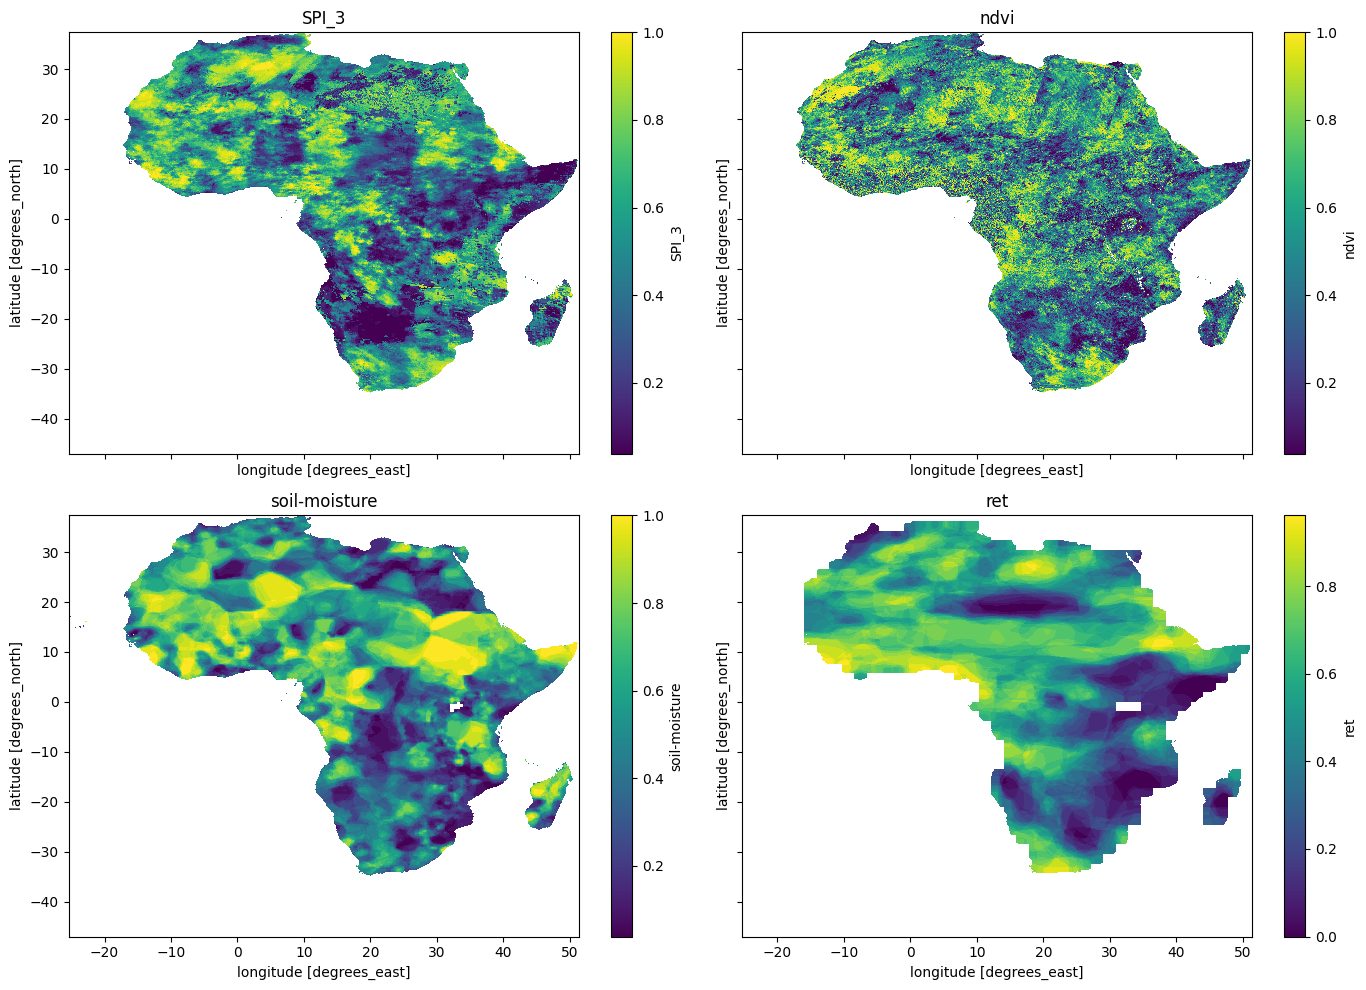

In [20]:
# 1. Select a target time slice
ds_pct_slice = ds_percentiles.isel(time=200)
slice_label = pd.to_datetime(ds_pct_slice["time"].values).strftime("%Y-%m")

# 2. Set up a 2x2 grid of subplots
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10), sharex=True, sharey=True)
axes_flat = axes.flatten()

# 3. Loop over the four data variables and plot each on a fixed [0, 1] percentile scale
for i, var_name in enumerate(ds_pct_slice.data_vars):
    if i < 4:  # Safety boundary for 4 variables
        ds_pct_slice[var_name].plot(ax=axes_flat[i], vmin=0, vmax=1, cmap="RdYlBu")
        axes_flat[i].set_title(var_name)

# 4. Add window context to figure title and render
fig.suptitle(
    f"CDI-{window}m Input Percentiles ({spi_var} + {window}-mo surface inputs) — {slice_label}",
    fontsize=13,
    y=1.01,
)
plt.tight_layout()
plt.show()

# Conduct Principal Component Analysis (PCA)

# Weights per cell

Conduct PCA on each cell to capture spatial variation in weights as well as temporal.

In [21]:
var_names = ["ndvi", spi_var, "soil-moisture", "ret"]

y_dim = "latitude" if "latitude" in ds_percentiles.sizes else "y"
x_dim = "longitude" if "longitude" in ds_percentiles.sizes else "x"

n_lat = ds_percentiles.sizes[y_dim]
n_lon = ds_percentiles.sizes[x_dim]

# Pre-allocate output arrays in float32 for weights and diagnostics: (month: 12, y, x)
w_out = {v: np.full((12, n_lat, n_lon), np.nan, dtype=np.float32) for v in var_names}

diag_vars = ["pc1_var_pct", "pc2_var_pct", "eigen_gap_pct", "n_years", "same_sign"]
d_out = {d: np.full((12, n_lat, n_lon), np.nan, dtype=np.float32) for d in diag_vars}

for m in range(1, 13):
    ds_m = ds_percentiles.sel(time=ds_percentiles["time.month"] == m)
    arrs = [ds_m[v].values for v in var_names]

    for i in range(n_lat):
        for j in range(n_lon):
            cell_data = np.column_stack([a[:, i, j] for a in arrs])
            cell_clean = cell_data[~np.isnan(cell_data).any(axis=1)]

            if cell_clean.shape[0] < 3 or np.any(np.std(cell_clean, axis=0) == 0):
                continue

            corr_matrix = np.corrcoef(cell_clean, rowvar=False)
            if np.isnan(corr_matrix).any():
                continue

            # eigh returns eigenvalues in ascending order: [-1] is PC1, [-2] is PC2
            evals, evecs = np.linalg.eigh(corr_matrix)
            v1 = evecs[:, -1]

            v1 = v1 / np.linalg.norm(v1)
            w = (v1**2) / np.sum(v1**2)

            # 1. Populate weights
            for idx, v in enumerate(var_names):
                w_out[v][m - 1, i, j] = w[idx]

            # 2. Populate diagnostics
            total_evals = np.sum(evals)
            pc1_pct = (evals[-1] / total_evals) * 100.0
            pc2_pct = (evals[-2] / total_evals) * 100.0

            d_out["pc1_var_pct"][m - 1, i, j] = pc1_pct
            d_out["pc2_var_pct"][m - 1, i, j] = pc2_pct
            d_out["eigen_gap_pct"][m - 1, i, j] = pc1_pct - pc2_pct
            d_out["n_years"][m - 1, i, j] = cell_clean.shape[0]
            d_out["same_sign"][m - 1, i, j] = float(np.all(v1 > 0) or np.all(v1 < 0))

shared_coords = {
    "month": np.arange(1, 13),
    y_dim: ds_percentiles[y_dim],
    x_dim: ds_percentiles[x_dim],
}

# Dataset 1: Clean operational weights
ds_monthly_weights = xr.Dataset(
    {v: (("month", y_dim, x_dim), w_out[v]) for v in var_names},
    coords=shared_coords,
)

# Dataset 2: Cell-level PCA diagnostics
ds_pca_diagnostics = xr.Dataset(
    {d: (("month", y_dim, x_dim), d_out[d]) for d in diag_vars},
    coords=shared_coords,
)

# Preserve spatial_ref coordinate if present on ds_percentiles
if "spatial_ref" in ds_percentiles.coords:
    ds_monthly_weights = ds_monthly_weights.assign_coords(
        spatial_ref=ds_percentiles["spatial_ref"]
    )
    ds_pca_diagnostics = ds_pca_diagnostics.assign_coords(
        spatial_ref=ds_percentiles["spatial_ref"]
    )

del w_out, d_out
gc.collect()

ds_monthly_weights

/opt/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/opt/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/opt/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/opt/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/opt/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/opt/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/opt/venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3045: Runt

### Check cell weights sum to 1

In [22]:
# Sum across the 4 variables at every (month, latitude, longitude)
weight_sum = (
    ds_monthly_weights["ndvi"]
    + ds_monthly_weights[spi_var]
    + ds_monthly_weights["soil-moisture"]
    + ds_monthly_weights["ret"]
)

# Check only non-NaN (land) cells
valid_sums = weight_sum.values[~np.isnan(weight_sum.values)]

print(f"[CDI-{window}m | {spi_var}] Weight sum check:")
print(f"  Min sum: {valid_sums.min():.6f}")
print(f"  Max sum: {valid_sums.max():.6f}")
print(f"  All valid cells sum to 1.0: {np.allclose(valid_sums, 1.0, atol=1e-5)}")

Min sum: 0.9999999999999996
Max sum: 1.0000000000000002
All valid cells sum to 1.0: True


## Plot cell diagnostics

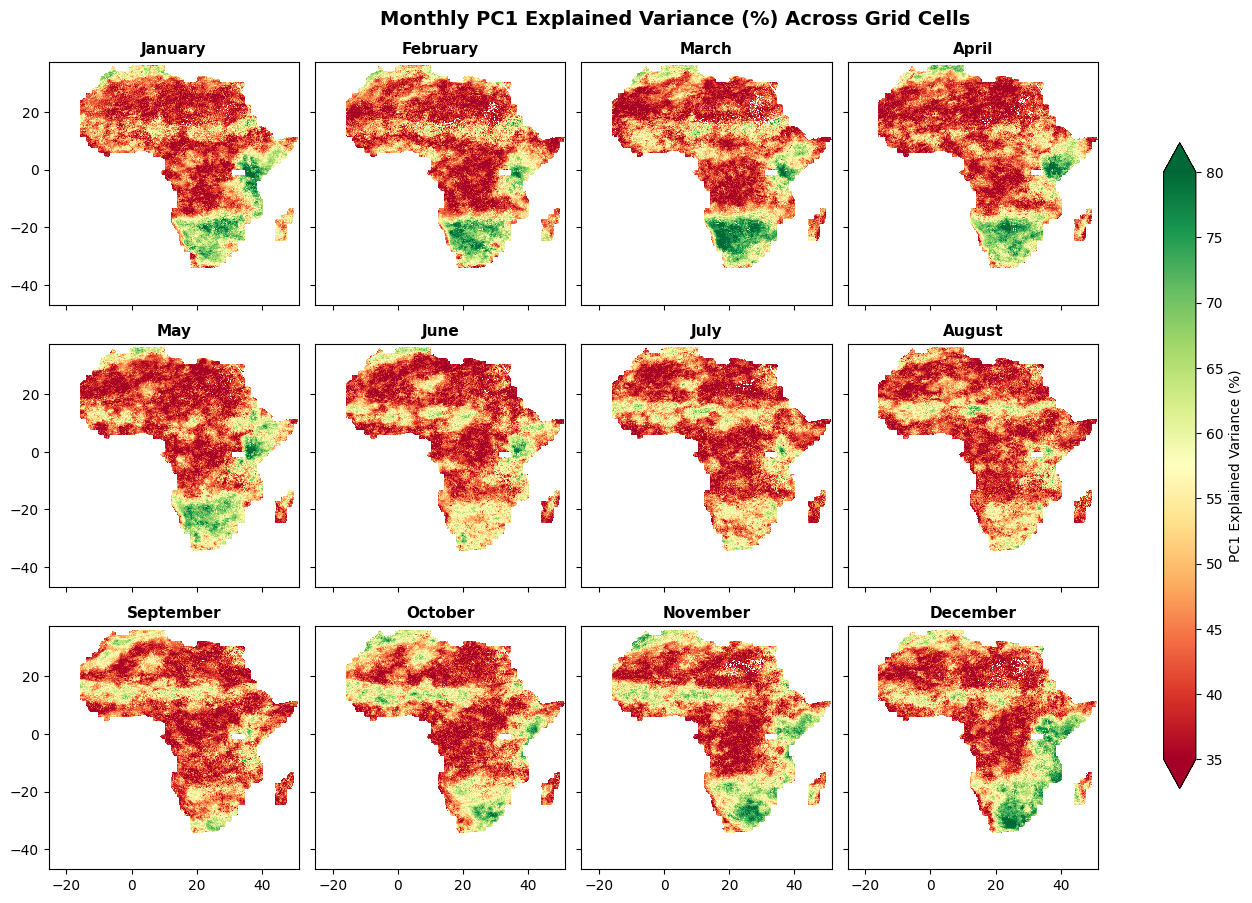

In [23]:
g = ds_pca_diagnostics["pc1_var_pct"].plot(
    col="month",
    col_wrap=4,
    figsize=(14, 9),
    cmap="RdYlGn",
    vmin=35.0,  # Below ~35-40% signals weak physical coupling (random = 25%)
    vmax=80.0,
    cbar_kwargs={"label": "PC1 Explained Variance (%)", "shrink": 0.8},
)

for m, ax in zip(range(1, 13), g.axs.flat):
    ax.set_title(calendar.month_name[m], fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")

g.fig.suptitle(
    f"CDI-{window}m ({spi_var} + {window}-mo surface inputs) — Monthly PC1 Explained Variance (%)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=150, constrained_layout=True)

# Panel A: Minimum Eigenvalue Gap (PC1 - PC2) across all 12 months
ds_pca_diagnostics["eigen_gap_pct"].min(dim="month").plot(
    ax=axes[0],
    cmap="magma",
    vmin=0,
    vmax=50,
    cbar_kwargs={"label": "Min PC1 - PC2 Gap (%)"},
)
axes[0].set_title("Worst-Case Eigenvalue Separation", fontweight="bold")

# Panel B: Fraction of months where all 4 variables share the same sign
(ds_pca_diagnostics["same_sign"].mean(dim="month") * 100.0).plot(
    ax=axes[1],
    cmap="Blues",
    vmin=0,
    vmax=100,
    cbar_kwargs={"label": "Same-Sign Months (%)"},
)
axes[1].set_title("Physical Sign Consistency", fontweight="bold")

# Panel C: Minimum valid years (N) across all 12 months
ds_pca_diagnostics["n_years"].min(dim="month").plot(
    ax=axes[2],
    cmap="viridis",
    vmin=3,
    vmax=25,
    cbar_kwargs={"label": "Min Valid Years (N)"},
)
axes[2].set_title("Minimum Sample Size (Cloudiest Month)", fontweight="bold")

for ax in axes:
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

fig.suptitle(
    f"CDI-{window}m ({spi_var} + {window}-mo surface inputs) — PCA Stability Diagnostics",
    fontsize=13,
    fontweight="bold",
)
plt.show()

## Plot weights through time

Ribbons represent spatial variability.

In [ ]:
ds_plot = ds_monthly_weights

y_dim = "latitude" if "latitude" in ds_plot.sizes else "y"
x_dim = "longitude" if "longitude" in ds_plot.sizes else "x"

var_names = ["ndvi", spi_var, "soil-moisture", "ret"]
labels = {
    "ndvi": "NDVI",
    spi_var: f"SPI-{spi_window}",
    "soil-moisture": "Soil Moisture",
    "ret": "RET",
}
colors = {
    "ndvi": "#2ca02c",          # Green
    spi_var: "#1f77b4",         # Blue
    "soil-moisture": "#8c564b", # Brown
    "ret": "#d62728",           # Red
}

months = ds_plot["month"].values
month_names = [calendar.month_abbr[m] for m in months]

fig, ax = plt.subplots(figsize=(10, 5.5), dpi=150)

for v in var_names:
    # Spatial mean and standard deviation across all valid land cells
    mean_w = ds_plot[v].mean(dim=[y_dim, x_dim], skipna=True).values
    std_w = ds_plot[v].std(dim=[y_dim, x_dim], skipna=True).values

    # Clip ribbon bounds to [0, 1] since weights cannot be negative or > 1
    lower = np.clip(mean_w - std_w, 0.0, 1.0)
    upper = np.clip(mean_w + std_w, 0.0, 1.0)

    ax.plot(
        months,
        mean_w,
        label=labels[v],
        color=colors[v],
        linewidth=2.2,
        marker="o",
        markersize=5,
    )
    ax.fill_between(
        months,
        lower,
        upper,
        color=colors[v],
        alpha=0.18,
    )

# Equal-weight reference line (0.25)
ax.axhline(0.25, color="gray", linestyle="--", linewidth=1, alpha=0.6, label="Equal Weight (0.25)")

ax.set_xticks(months)
ax.set_xticklabels(month_names)
ax.set_xlim(1, 12)
ax.set_ylim(0, 0.65)  # Adjust upper limit if any weight peak exceeds 0.65
ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("PCA Weight (±1 SD across cells)", fontsize=11)
ax.set_title(
    f"CDI-{window}m ({spi_var} + {window}-mo surface inputs) — Monthly PCA Variable Weights",
    fontsize=13,
    fontweight="bold",
)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(frameon=True, ncol=2, fontsize=10)

plt.tight_layout()
plt.show()

## Create spatial plot of weights

In [ ]:
# Select the month you want to inspect (1 = Jan, ..., 8 = Aug)
selected_month = 7

var_names = ["ndvi", spi_var, "soil-moisture", "ret"]
titles = {
    "ndvi": "NDVI Weight",
    spi_var: f"SPI-{spi_window} Weight",
    "soil-moisture": "Soil Moisture Weight",
    "ret": "RET Weight",
}

ds_m = ds_monthly_weights.sel(month=selected_month)

fig, axes = plt.subplots(2, 2, figsize=(12, 9), dpi=150, constrained_layout=True)

for ax, v in zip(axes.flat, var_names):
    im = ds_m[v].plot(
        ax=ax,
        cmap="viridis",
        vmin=0.0,
        vmax=0.6,  # Adjust if individual cell weights peak higher
        add_colorbar=False,
    )
    ax.set_title(titles[v], fontsize=12, fontweight="bold")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

# Single shared colorbar across all 4 subplots
cbar = fig.colorbar(im, ax=axes, orientation="vertical", fraction=0.025, pad=0.03)
cbar.set_label("PCA Weight", fontsize=11)

month_name = calendar.month_name[selected_month]
fig.suptitle(
    f"CDI-{window}m ({spi_var} + {window}-mo surface inputs) — Spatial PCA Weights ({month_name})",
    fontsize=13,
    fontweight="bold",
)

plt.show()

## PCA Diagnostics

In [ ]:
var_names = ["ndvi", spi_var, "soil-moisture", "ret"]

print(f"=== Quality Checks: CDI-{window}m ({spi_var} + {window}-mo surface inputs) ===\n")

# 1. Check mask consistency across all 12 months
mask_per_month = ds_monthly_weights["ndvi"].notnull()
consistent_mask = (mask_per_month.sum(dim="month") == 12) | (mask_per_month.sum(dim="month") == 0)
print("1. Mask consistent across all 12 months:", bool(consistent_mask.all()))
if not bool(consistent_mask.all()):
    inconsistent_cells = int((~consistent_mask).sum())
    print(f"   -> Warning: {inconsistent_cells} cells have weights in some months but NaN in others.")

# 2. Check weight bounds & extreme dominance (0.0 to 1.0)
print("\n2. Weight Ranges Across All Valid Cells & Months:")
for v in var_names:
    vals = ds_monthly_weights[v].values
    vals = vals[~np.isnan(vals)]
    print(
        f"   {v:15s} | min: {vals.min():.3f} | median: {np.median(vals):.3f} "
        f"| p99: {np.percentile(vals, 99):.3f} | max: {vals.max():.3f}"
    )

# 3. Check valid sample count (N years) in cloudiest month (e.g., Aug) vs driest month (e.g., Jan)
for m in [1, 8]:
    ds_m = ds_percentiles[var_names].sel(time=ds_percentiles["time.month"] == m)
    valid_all = (
        ds_m["ndvi"].notnull()
        & ds_m[spi_var].notnull()
        & ds_m["soil-moisture"].notnull()
        & ds_m["ret"].notnull()
    )
    n_years = valid_all.sum(dim="time").values
    land_n = n_years[n_years > 0]
    print(
        f"\n3. Valid overlapping years (Month {m}): "
        f"min={land_n.min()}, median={np.median(land_n):.0f}, max={land_n.max()}"
    )

# Export COGs

In [ ]:
os.makedirs("data", exist_ok=True)
var_names = ["ndvi", spi_var, "soil-moisture", "ret"]

for i in range(len(ds_monthly_weights.month)):
    # Extract the integer month number (1 to 12)
    m = int(ds_monthly_weights.month.isel(month=i).item())
    fname = f"data/cdi_{window}m_weights_month_{m:02d}.tif"
    print(f"Writing {fname} (bands: {var_names})")

    # Enforce explicit band order: (variable, y, x) 
    single_month = ds_monthly_weights[var_names].isel(month=i).to_array().astype("float32")

    # Write Cloud-Optimized GeoTIFF via datacube.utils.cog.write_cog
    write_cog(single_month, fname=fname, overwrite=True)

In [ ]:
os.makedirs("data", exist_ok=True)
diag_vars = ["pc1_var_pct", "pc2_var_pct", "eigen_gap_pct", "n_years", "same_sign"]

for i in range(len(ds_pca_diagnostics.month)):
    # Extract the integer month number (1 to 12)
    m = int(ds_pca_diagnostics.month.isel(month=i).item())
    fname = f"data/pca_{window}m_diagnostics_month_{m:02d}.tif"
    print(f"Writing {fname} (bands: {diag_vars})")

    # Enforce explicit band order: (variable, y, x) in float32
    single_month = ds_pca_diagnostics[diag_vars].isel(month=i).to_array().astype("float32")

    # Write Cloud-Optimized GeoTIFF via datacube.utils.cog.write_cog
    write_cog(single_month, fname=fname, overwrite=True)

***

## Additional information

**License:** The code in this notebook is licensed under the [Apache License, Version 2.0](https://www.apache.org/licenses/LICENSE-2.0). 
Digital Earth Africa data is licensed under the [Creative Commons by Attribution 4.0](https://creativecommons.org/licenses/by/4.0/) license.

**Contact:** If you need assistance, please post a question on the [Open Data Cube Slack channel](http://slack.opendatacube.org/) or on the [GIS Stack Exchange](https://gis.stackexchange.com/questions/ask?tags=open-data-cube) using the `open-data-cube` tag (you can view previously asked questions [here](https://gis.stackexchange.com/questions/tagged/open-data-cube)).
If you would like to report an issue with this notebook, you can file one on [Github](https://github.com/digitalearthafrica/deafrica-sandbox-notebooks).

**Compatible datacube version:** 

In [ ]:
print(datacube.__version__)

**Last Tested:**

In [ ]:
from datetime import datetime
datetime.today().strftime('%Y-%m-%d')